# Week 1: the prompt-only baseline

**Question.** Before building anything, how well does the model do with just a good prompt?

Four prompting strategies, same model (Qwen3-8B), same 57 dev rows, no tools and no sources:

| Strategy | Idea |
|---|---|
| S0 zero-shot | Rules in the system prompt, nothing else |
| S1 few-shot | Plus worked examples |
| S2 self-consistency | Three samples, majority vote |
| S3 decomposition | Classify first, then answer |

**Business reading.** This is the "just paste it into a chatbot" option. It sets the bar every later week must clear.

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.environ.setdefault("RTO_HOME", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rto_copilot import config, nbkit
from rto_copilot.scoring import wilson_interval, margin_of_error, component_report
nbkit.style()
pd.set_option("display.max_colwidth", 90, "display.width", 140)
config.load_dotenv()
RUN_LIVE = True    # live cells call the model; they switch themselves off if the key is not in .env yet
if RUN_LIVE and config.missing_llm_env():
    print("RUN_LIVE switched off: set", ", ".join(config.missing_llm_env()), "in .env, then restart the kernel.")
    RUN_LIVE = False
print("Project root:", ROOT)

RUN_LIVE switched off: set LLM_API_KEY in .env, then restart the kernel.
Project root: /home/claude/v3/RTO_SmartTransfer_v3


In [2]:
base = pd.read_csv(config.RESULTS / "baseline/week1_qwen3_8b/summary.csv")
base["k"] = (base.end_to_end_accuracy * base["items"]).round().astype(int)
base["label"] = base.strategy.str.replace("_", "\n", n=1)
base[["strategy", "items", "end_to_end_accuracy", "behavior_accuracy", "must_include_coverage", "citation_ok_rate", "avg_latency_s", "avg_tokens"]].round(3)

,strategy,items,end_to_end_accuracy,behavior_accuracy,must_include_coverage,citation_ok_rate,avg_latency_s,avg_tokens
0,S0_ZERO_SHOT,57,0.175,0.579,0.593,0.772,6.279,3014.421
1,S1_FEW_SHOT,57,0.246,0.649,0.606,0.825,4.113,4401.702
2,S2_SELF_CONSISTENCY,57,0.211,0.544,0.587,0.772,20.113,9270.544
3,S3_DECOMPOSITION,57,0.193,0.561,0.568,0.754,13.335,6483.000


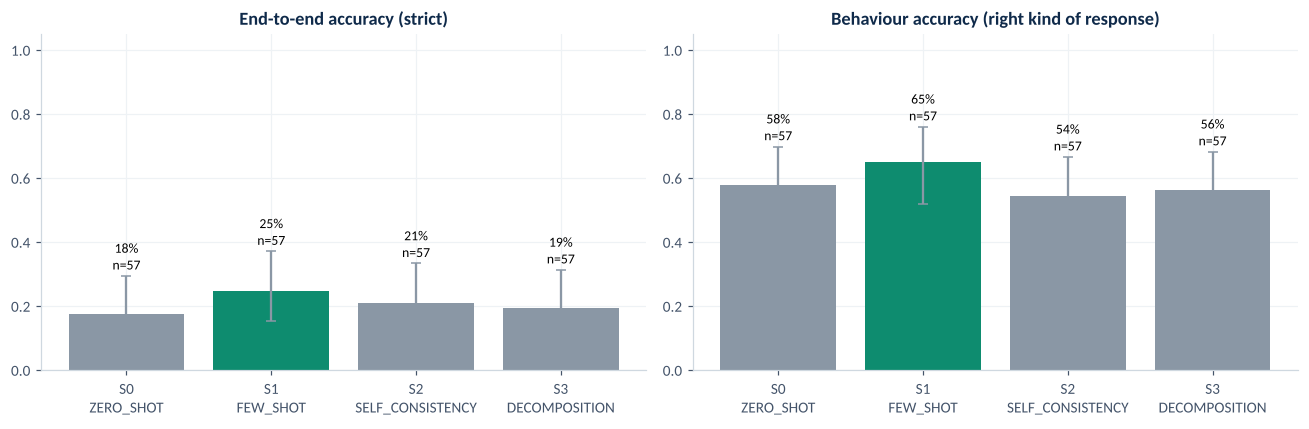

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
nbkit.ci_bars(axes[0], base.label, base.k, base["items"], colors=[nbkit.GREY, nbkit.TEAL, nbkit.GREY, nbkit.GREY])
axes[0].set_title("End-to-end accuracy (strict)")
kb = (base.behavior_accuracy * base["items"]).round().astype(int)
nbkit.ci_bars(axes[1], base.label, kb, base["items"], colors=[nbkit.GREY, nbkit.TEAL, nbkit.GREY, nbkit.GREY])
axes[1].set_title("Behaviour accuracy (right kind of response)")
plt.tight_layout(); plt.show()

**Read-out.** Few-shot is best, and the extra machinery (voting, decomposition) did *not* help: more calls, more tokens,
no gain. All four intervals overlap heavily, so do not over-read the ranking. What is solid is the level: roughly one
row in five passes every check. The model does not know what it does not know, and it cannot cite sources it has not been given.

## Where does a baseline row lose its point?

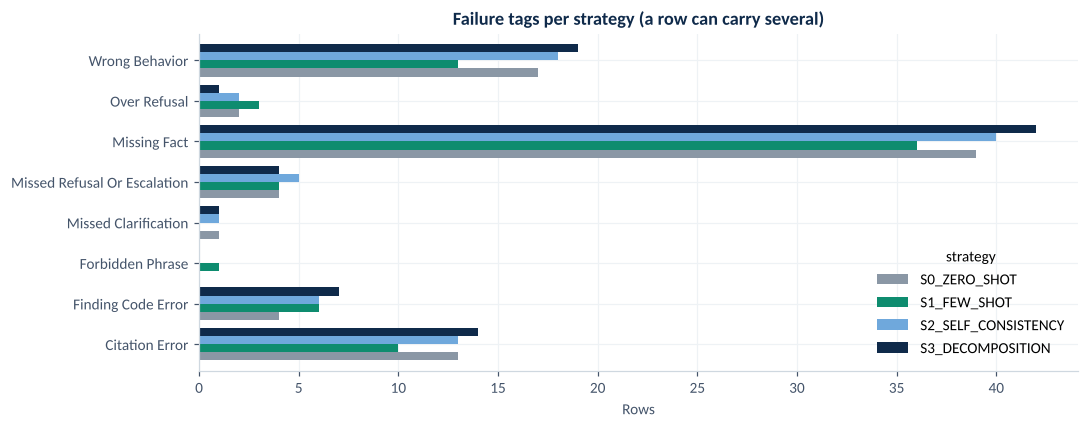

In [4]:
fail = base.set_index("strategy")[[c for c in base.columns if c.startswith("fail_")]]
fail.columns = [c.replace("fail_", "").replace("_", " ").title() for c in fail.columns]
fig, ax = plt.subplots(figsize=(10, 4))
fail.T.plot.barh(ax=ax, width=0.8, color=[nbkit.GREY, nbkit.TEAL, nbkit.SKY, nbkit.NAVY])
ax.set_title("Failure tags per strategy (a row can carry several)"); ax.set_xlabel("Rows"); plt.tight_layout(); plt.show()

**Missing fact** dominates: the answer is plausible but misses a required item (a form number, a date, a section).
**Wrong behaviour** (answering when it should clarify or refuse, or the reverse) and **citation errors** (sources that are
wrong or that it never saw) follow. Together they are *grounding* problems,
which is exactly what Week 2 (retrieval) and Week 3 (tools) attack.

## Cost of each strategy

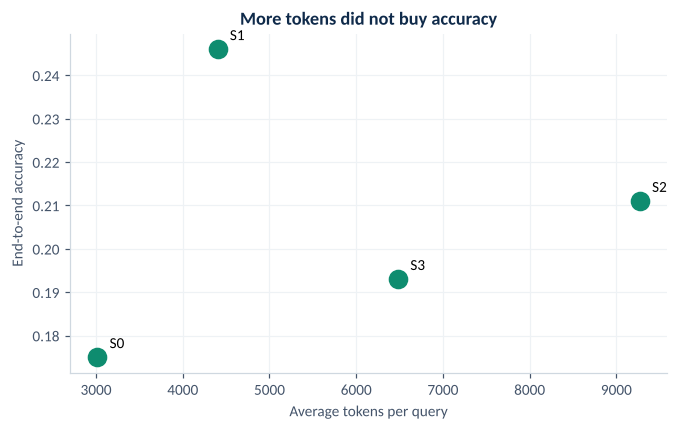

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(base.avg_tokens, base.end_to_end_accuracy, s=140, color=nbkit.TEAL)
for _, r in base.iterrows():
    ax.annotate(r.strategy.split("_")[0], (r.avg_tokens, r.end_to_end_accuracy), textcoords="offset points", xytext=(8, 6))
ax.set_xlabel("Average tokens per query"); ax.set_ylabel("End-to-end accuracy"); ax.set_title("More tokens did not buy accuracy"); plt.show()

## A concrete failing row

In [6]:
v1 = pd.read_csv(config.eval_path("v1")).set_index("query_id")
rows = nbkit.load_jsonl(config.RESULTS / "baseline/week1_qwen3_8b/S1_FEW_SHOT.jsonl")
bad = next(r for r in rows if not r["end_to_end"] and r["failure_tags"] and "MISSING_FACT" in r["failure_tags"])
print("Query    :", v1.loc[bad["query_id"], "query"])
print("Gold     :", v1.loc[bad["query_id"], "gold_answer"][:300])
print("Must have:", v1.loc[bad["query_id"], "must_include"])
print("Tags     :", bad["failure_tags"])
print("Model    :", str(bad["raw"])[:450])

Query    : What is Form 30 used for?
Gold     : Form 30 is the transferee's (buyer's) report and application for transfer of ownership. For a vehicle registered in the same State the buyer files it with the registering authority along with the supporting documents and fee. Where the vehicle is under hypothecation, the form also carries the financ
Must have: buyer|transferee;transfer of ownership;financier
Tags     : MISSING_FACT
Model    : {"behavior": "ANSWER", "answer": "Form 30 is used by the buyer (transferee) to apply for the transfer of ownership of a vehicle. It is submitted to the registering authority (RTO) within 14 days of the sale, along with the original Registration Certificate (RC), valid insurance, PUC certificate, and other required documents.", "citations": [{"source_id": "SRC-PARIVAHAN-TO", "locator": ""}, {"source_id": "SRC-WB-FAQ", "locator": ""}], "findings": 


## Live: re-run the baseline (optional)

Needs the endpoint. Uses the v2 dev rows (96 after excluding the few-shot exemplars). Results go to `results/baseline/`.
The test split is gated: it only runs on a frozen eval set.

In [7]:
import subprocess
cmd = [sys.executable, "-m", "rto_copilot.baseline", "--split", "dev", "--cohort", "v2"]
print("Command:", " ".join(cmd), "\n(cohort v2 = only the new rows; drop --cohort to score all dev rows)")
if RUN_LIVE:
    env = {**os.environ, "RTO_EVAL_SET": "v2", "PYTHONPATH": str(ROOT / "src")}
    print(subprocess.run(cmd, capture_output=True, text=True, env=env, cwd=ROOT).stdout[-3000:])

Command: /usr/local/bin/python3 -m rto_copilot.baseline --split dev --cohort v2 
(cohort v2 = only the new rows; drop --cohort to score all dev rows)
